# Sentiment and Verbosity in Federal Reserve (FOMC) Statements

Do central bankers say more – and sound gloomier – when the economy is in trouble? This notebook applies
dictionary-based text analytics to 169 Federal Open Market Committee post-meeting statements (2005–2024), measuring
each statement's net sentiment and length over time and relating both to major macroeconomic events.

**Methods:** text cleaning with regex · tokenisation and lemmatisation (NLTK) · stop-word removal ·
dictionary-based sentiment scoring with the Loughran–McDonald financial word lists · time-series visualisation.

## Folder structure

Paths are relative to the repo root:
```
data/FOMC_statements.csv     # statement text + date (included)
data/stopwords.csv           # common English stop words (included)
data/positive_words.csv      # Loughran–McDonald positive words (not redistributed – see README)
data/negative_words.csv      # Loughran–McDonald negative words (not redistributed – see README)
```

In [1]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# NLTK for tokenisation and lemmatisation
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("wordnet", quiet=True)
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

lemmatiser = WordNetLemmatizer()
os.makedirs("figures", exist_ok=True)

## 1. Load the statements

In [2]:
fomc = pd.read_csv("data/FOMC_statements.csv")
print(f"Dataset shape: {fomc.shape}")
print(f"Columns: {fomc.columns.tolist()}")

# Combine year_month and day into one datetime column so statements can be sorted chronologically
fomc["date"] = pd.to_datetime(fomc["year_month"].astype(str) + "-" + fomc["day"].astype(str), format="%Y-%m-%d")
fomc = fomc.sort_values("date").reset_index(drop=True)

print(f"Date range: {fomc['date'].min().date()} to {fomc['date'].max().date()}")
print(f"Number of statements: {len(fomc)}")

# Raw word count per statement
fomc["word_count"] = fomc["Text"].apply(lambda t: len(str(t).split()))
print("\nRaw statement length (words):")
print(fomc["word_count"].describe().round(1))

Dataset shape: (169, 3)
Columns: ['Text', 'year_month', 'day']
Date range: 2005-02-02 to 2024-12-18
Number of statements: 169

Raw statement length (words):
count    169.0
mean     440.1
std      163.6
min       78.0
25%      325.0
50%      426.0
75%      541.0
max      903.0
Name: word_count, dtype: float64


## 2. Load and prepare the word lists

The **Loughran–McDonald** dictionary is used instead of a general-purpose sentiment lexicon (such as VADER)
because words like *risk* or *liability* are negative in everyday English but neutral in financial writing.
All lists are lower-cased so they match the cleaned text, and the positive and negative lists are checked for
overlap.

In [3]:
positive_words_df = pd.read_csv("data/positive_words.csv")
negative_words_df = pd.read_csv("data/negative_words.csv")
stopwords_df = pd.read_csv("data/stopwords.csv")

# Lower-case everything to remove case disparities between files
positive_words = set(positive_words_df["positive_words"].str.lower())
negative_words = set(negative_words_df["negative_words"].str.lower())
stop_words = set(stopwords_df["stopwords"].str.lower())

print(f"Positive words: {len(positive_words):,}")
print(f"Negative words: {len(negative_words):,}")
print(f"Stop words:     {len(stop_words):,}")
print(f"Words in both sentiment lists: {len(positive_words & negative_words)}")

Positive words: 354
Negative words: 2,355
Stop words:     121
Words in both sentiment lists: 0


## 3. Clean and tokenise the statements

Each step and the problem it solves:

| Step | Why |
|---|---|
| Lower-case | otherwise *Inflation* and *inflation* are different tokens, inflating counts and breaking dictionary matches |
| Remove punctuation, numbers and special characters (regex) | so words tokenise cleanly and match the dictionaries |
| Collapse whitespace | removes empty tokens left behind by the regex |
| Tokenise | splits text into words, needed for matching and lemmatisation |
| Remove stop words and 1-letter tokens | words like *a* or *the* carry no sentiment and would inflate length |
| Lemmatise (verb then noun) | maps *raised/raising* → *raise*, so inflected forms match the dictionary |

In [4]:
def preprocess(text, stop_words):
    # Lower-case, then replace anything that is not a letter or whitespace with a space
    text = re.sub(r"[^a-z\s]", " ", str(text).lower())
    # Collapse runs of whitespace into a single space
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)

    # Remove stop words and single-character tokens
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]

    # Lemmatise as a verb, then as a noun
    tokens = [lemmatiser.lemmatize(lemmatiser.lemmatize(t, pos="v"), pos="n") for t in tokens]
    return tokens


fomc["tokens"] = fomc["Text"].apply(lambda t: preprocess(t, stop_words))
fomc["token_count"] = fomc["tokens"].apply(len)

print("First 20 tokens of the earliest statement:")
print(fomc["tokens"].iloc[0][:20])

reduction = 1 - fomc["token_count"].mean() / fomc["word_count"].mean()
print(f"\nAverage words before cleaning: {fomc['word_count'].mean():.1f}")
print(f"Average tokens after cleaning: {fomc['token_count'].mean():.1f}  ({reduction * 100:.1f}% reduction)")

First 20 tokens of the earliest statement:
['release', 'date', 'february', 'immediate', 'release', 'federal', 'open', 'market', 'committee', 'decide', 'today', 'raise', 'target', 'federal', 'fund', 'rate', 'basis', 'point', 'percent', 'committee']

Average words before cleaning: 440.1
Average tokens after cleaning: 279.2  (36.6% reduction)


## 4. Sentiment score

For each statement, positive and negative dictionary hits are counted and the net sentiment is scaled by the
statement's total number of cleaned tokens:

$$\text{sentiment} = \frac{N_{pos} - N_{neg}}{N_{tokens}}$$

Scaling by total tokens makes the score a measure of net *tone density*, comparable across statements of very
different lengths.

In [5]:
def compute_sentiment(tokens, positive_words, negative_words):
    n_total = len(tokens)
    if n_total == 0:
        return 0.0
    n_pos = sum(1 for t in tokens if t in positive_words)
    n_neg = sum(1 for t in tokens if t in negative_words)
    return (n_pos - n_neg) / n_total


fomc["sentiment"] = fomc["tokens"].apply(lambda x: compute_sentiment(x, positive_words, negative_words))
print("Sentiment summary statistics:")
print(fomc["sentiment"].describe().round(4))

Sentiment summary statistics:
count    169.0000
mean       0.0040
std        0.0141
min       -0.0395
25%       -0.0045
50%        0.0053
75%        0.0132
max        0.0332
Name: sentiment, dtype: float64


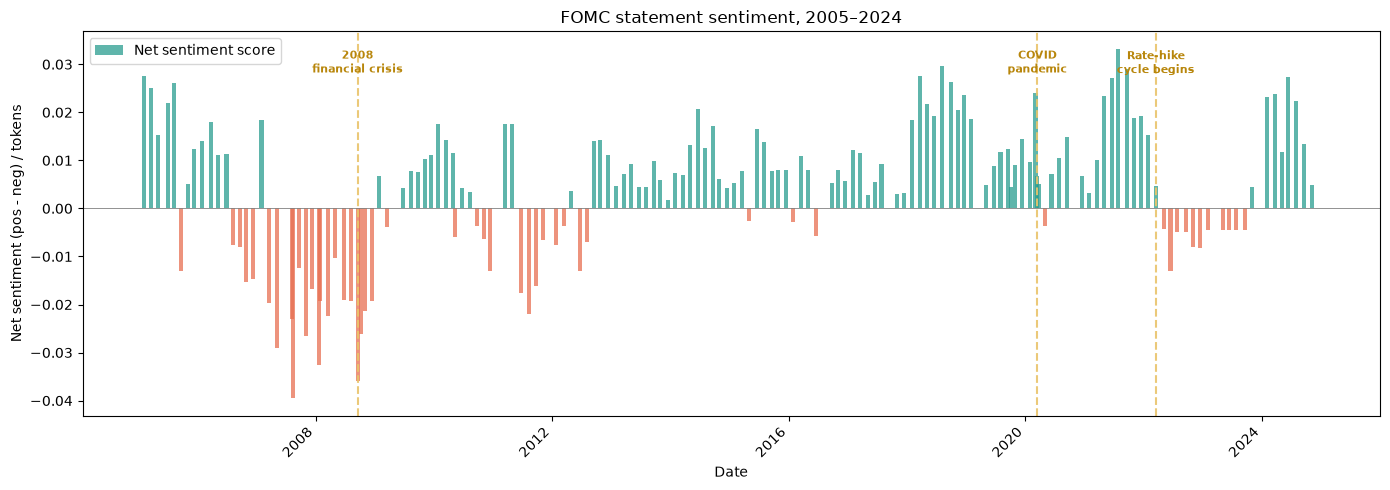

In [6]:
bar_colours = ["#2a9d8f" if s >= 0 else "#e76f51" for s in fomc["sentiment"]]

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(fomc["date"], fomc["sentiment"], width=25, color=bar_colours, alpha=0.75, label="Net sentiment score")
ax.axhline(0, color="grey", linewidth=0.6)

events = [
    ("2008-09-16", "2008\nfinancial crisis"),
    ("2020-03-15", "COVID\npandemic"),
    ("2022-03-16", "Rate-hike\ncycle begins"),
]
for date_str, label in events:
    xval = pd.Timestamp(date_str)
    ax.axvline(xval, color="#e9c46a", linewidth=1.5, linestyle="--", alpha=0.9)
    ax.text(xval, ax.get_ylim()[1] * 0.90, label, ha="center", va="top", fontsize=8, color="#b8860b", fontweight="bold")

ax.set_xlabel("Date")
ax.set_ylabel("Net sentiment (pos - neg) / tokens")
ax.set_title("FOMC statement sentiment, 2005–2024")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("figures/sentiment_over_time.png", dpi=150)
plt.show()

## 5. Verbosity over time

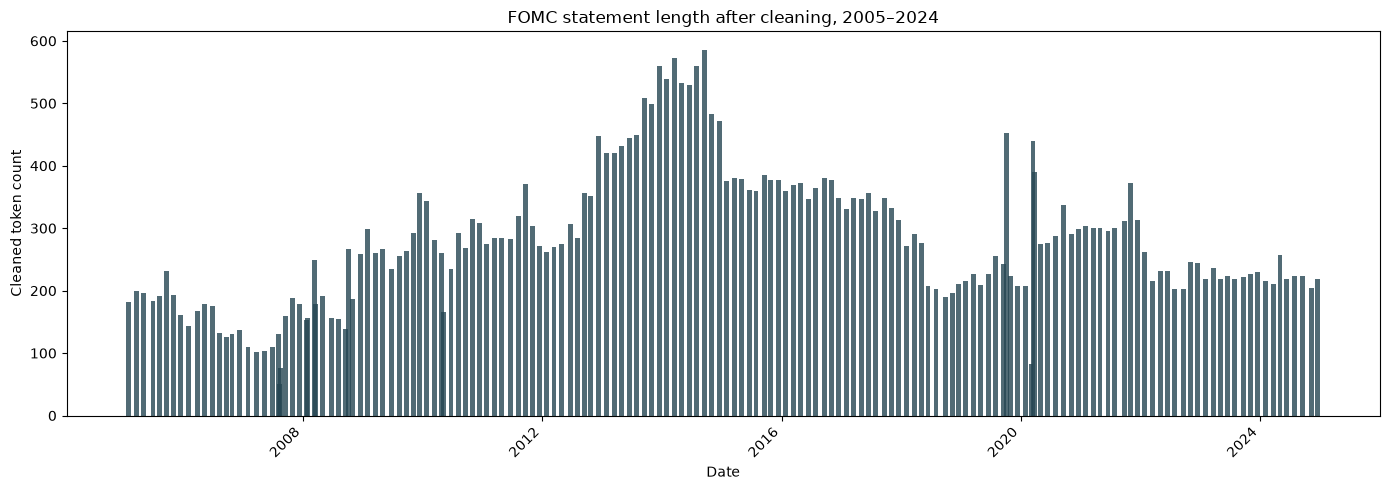

In [7]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(fomc["date"], fomc["token_count"], width=30, color="#264653", alpha=0.8)
ax.set_xlabel("Date")
ax.set_ylabel("Cleaned token count")
ax.set_title("FOMC statement length after cleaning, 2005–2024")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("figures/verbosity_over_time.png", dpi=150)
plt.show()

In [8]:
# Average length and sentiment by period
periods = pd.cut(
    fomc["date"].dt.year,
    bins=[2004, 2007, 2011, 2016, 2019, 2021, 2024],
    labels=["2005-07", "2008-11", "2012-16", "2017-19", "2020-21", "2022-24"],
)
by_period = fomc.groupby(periods, observed=True).agg(
    statements=("sentiment", "size"),
    mean_tokens=("token_count", "mean"),
    mean_sentiment=("sentiment", "mean"),
).round(4)
print(by_period)
print(f"\nCorrelation between length and sentiment: {fomc['token_count'].corr(fomc['sentiment']):.3f}")

         statements  mean_tokens  mean_sentiment
date                                            
2005-07          26     151.3846         -0.0007
2008-11          36     255.0278         -0.0052
2012-16          40     411.9500          0.0060
2017-19          25     272.2800          0.0127
2020-21          18     298.8889          0.0136
2022-24          24     224.9583          0.0035

Correlation between length and sentiment: 0.258
